In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import os
import csv

In [ ]:
drive.mount("/content/drive/")

Mounted at /content/drive/


In [ ]:
os.getcwd()

'/content'

In [ ]:
DIR = "/content/drive/MyDrive/Colab Notebooks/Métodos-Computacionales-1/data/"

In [ ]:
def csv_reader(name):
    x, y = [], []

    with open(DIR+name, "r") as f:
        reader = csv.reader(f)
        headers = next(reader)
        data = []
        for li in reader:
            d = [ float(di) for di in li]
            data.append(d)

    return np.array(data)

In [ ]:
d = csv_reader("01_movimiento_rectilineo_uniforme.csv")

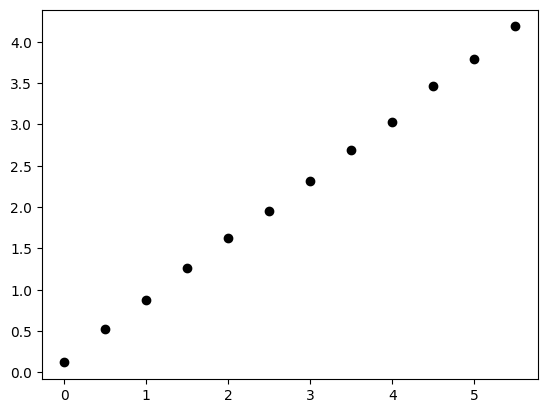

In [ ]:
plt.plot(d[:,0], d[:,1], "ok")

In [ ]:
def fit(x,y, n=1):
    phi = lambda n: np.column_stack([ x**i for i in range(n+1) ])
    ϕ = phi(n)
    M = ϕ.T @ ϕ
    b = ϕ.T @ y
    θ = np.linalg.solve(M,b)

    return ϕ, b, θ

def residuals(θ,x):
    pass


In [ ]:
x, y = d[:,0], d[:,1]
ϕ, b, θ = fit(x, y, n = 1)

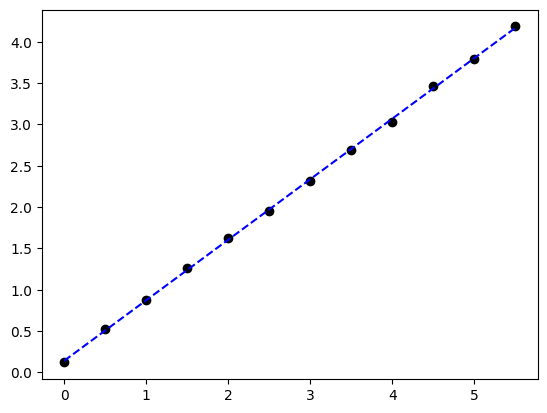

In [ ]:
_x = np.linspace( x.min(), x.max(), 100)
_y = sum( θi*_x**i for i,θi in enumerate(θ) )

plt.plot( x, y, "ok")
plt.plot( _x, _y, "--b")
plt.show()

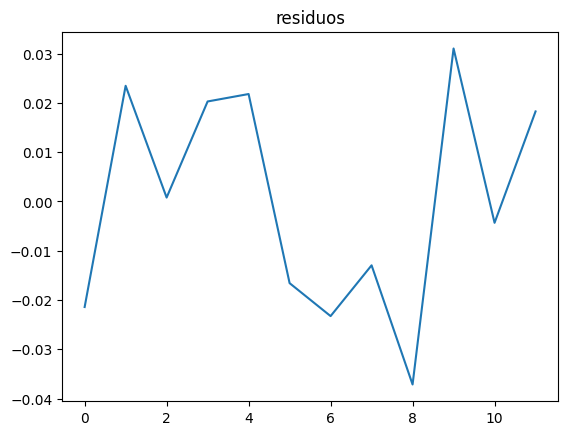

In [ ]:
plt.title("residuos")
plt.plot(y - ϕ@θ)
plt.show()

# Coeficiente de Pearson

In [ ]:
r = y - ϕ@θ
res2 = r.T@r

ym = y - y.mean()
SST = ym.T@ym

R2 = 1 - res2/SST

In [ ]:
R2

np.float64(0.9997087180522218)

In [ ]:
def F(X):
    return np.array([
        X[0]**2 + X[1]**2 - 4,
        X[0]*X[1] -1
    ])

def J(X):
    return np.array([
        [2*X[0], 2*X[1]],
        [X[1], X[0] ]
    ])

def NR_nonlinear(F, J, X0, maxiter=1000, eps =  1e-8):
    Xk = X0
    iters = [ Xk ]

    for k in range(maxiter):
        δ = np.linalg.solve(J(Xk), -F(Xk))
        Xk = Xk + δ
        iters.append(Xk)

        if np.linalg.norm(δ) < eps:
            break

    return Xk, iters

In [ ]:
NR_nonlinear(F,J, np.array([1.6,2.0]))

(array([0.51763809, 1.93185165]),
 [array([1.6, 2. ]),
  array([-0.03333333,  2.66666667]),
  array([0.3677684 , 2.08813877]),
  array([0.50402138, 1.94547675]),
  array([0.51750938, 1.93198036]),
  array([0.51763808, 1.93185166]),
  array([0.51763809, 1.93185165]),
  array([0.51763809, 1.93185165])])

In [ ]:
t = np.linspace(0.1,3,7)
X, Y = np.meshgrid( t, t )

for i in range(X.shape[0]):
    for j in range(i+1,Y.shape[1]):
        x, _ = NR_nonlinear(F,J, np.array([ X[i,j], Y[i,j] ]))
        print(x)

[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]
[1.93185165 0.51763809]


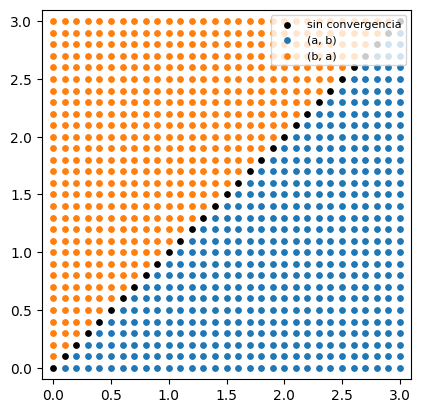

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def F(X):
    return np.array([
        X[0]**2 + X[1]**2 - 4,
        X[0]*X[1] - 1
    ])

def J(X):
    return np.array([
        [2*X[0], 2*X[1]],
        [X[1],   X[0]]
    ])

def NR_nonlinear(F, J, X0, maxiter=100, eps=1e-8):
    Xk = np.asarray(X0, dtype=float)
    iters = [Xk]

    for k in range(maxiter):
        try:
            δ = np.linalg.solve(J(Xk), -F(Xk))
        except np.linalg.LinAlgError:          # jacobiano singular
            return Xk, iters, False
        Xk = Xk + δ
        iters.append(Xk)

        if not np.all(np.isfinite(Xk)):        # divergencia
            return Xk, iters, False
        if np.linalg.norm(δ) < eps:
            return Xk, iters, True

    return Xk, iters, False                    # no convergió


# las cuatro raíces exactas
a, b = np.sqrt(2 + np.sqrt(3)), np.sqrt(2 - np.sqrt(3))
roots = np.array([[a, b], [b, a], [-a, -b], [-b, -a]])

n = 31
t = np.linspace(0, 3, n)
X, Y = np.meshgrid(t, t)

basin = np.full(X.shape, -1)
for i in range(n):
    for j in range(n):
        xk, iters, ok = NR_nonlinear(F, J, np.array([X[i, j], Y[i, j]]))
        if ok:
            d = np.linalg.norm(roots - xk, axis=1)
            if d.min() < 1e-6:
                basin[i, j] = d.argmin()

colors = np.array(["black", "tab:blue", "tab:orange", "tab:green", "tab:red"])
labels = ["sin convergencia", "(a, b)", "(b, a)", "(-a, -b)", "(-b, -a)"]

for k in range(-1, 4):
    mask = basin == k
    if mask.any():
        plt.scatter(X[mask], Y[mask], s=15, color=colors[k + 1], label=labels[k + 1])

plt.gca().set_aspect("equal")
plt.xlim(-0.1, 3.1); plt.ylim(-0.1, 3.1)
plt.legend(loc="upper right", fontsize=8)
plt.show()